# BoN vs PSP — generation cache + Best-of-N
Settings:
- Runtime → NVIDIA L4
- Upload `its_harness.zip` to the working environment
- All results are written to Google Drive to avoid any loss if there is disconnection.

## 1. Mount Drive and set paths

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJ  = '/content/drive/MyDrive/ai6132_its'
CACHE = f'{PROJ}/cache/sd15_geneval_T64'
RES   = f'{PROJ}/results_bon'
os.makedirs(PROJ, exist_ok=True)
print(os.listdir(PROJ))

Mounted at /content/drive
['prompts_run.jsonl', 'cache', 'results_bon', 'results_bon_bootstrap', 'handover', 'handover_bon.zip', 'results_bon_geneval', 'its_harness.zip', 'figures']


## 2. Check the GPU

In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
NVIDIA L4, 23034 MiB


## 3. Install packages

In [ ]:
!pip -q install "diffusers==0.31.0" "transformers==4.38.2" "huggingface_hub==0.25.2" "image-reward==1.5" "git+https://github.com/openai/CLIP.git"
!pip -q uninstall -y peft   # Colab's peft needs a newer transformers and breaks diffusers imports; we don't use it
import ImageReward, diffusers, transformers, torch
print('ok | torch', torch.__version__, '| diffusers', diffusers.__version__, '| transformers', transformers.__version__, '| cuda', torch.cuda.is_available())

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.25.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.25.2 which is incompatible.
sentence-transformers 5.7.0 requires tokenizers>=0.19, but you have tokenizers 0.15.2 which is incompatible.
sentence-transformers 5.7.0 requires transformers<6.0.0,>=4.41.0, but you have transformers 4.38.2 which is incompatible.
ok | torch 2.14.1+cu130 | diffusers 0.31.0 | transf

## 4. Unpack the harness to local disk

In [ ]:
import os, shutil
os.makedirs(PROJ, exist_ok=True)
if os.path.exists('/content/its_harness.zip'):
    shutil.copy('/content/its_harness.zip', f'{PROJ}/its_harness.zip')   # save a copy to Drive
!rm -rf /content/its_harness && unzip -q -o {PROJ}/its_harness.zip -d /content/
%cd /content/its_harness
!ls

/content/its_harness
bon_replay.py	   geneval_subset_120.jsonl  run_timing_test.sh
generate_cache.py  its_colab.ipynb
geneval_bridge.py  README.md


## 5. Timing test

In [ ]:
!BATCH_SIZE=16 bash run_timing_test.sh

I0000 00:00:1794194759.742770    2020 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794194761.395682    2020 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794194761.396230    2020 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
model_index.json: 100% 541/541 [00:00<00:00, 3.84MB/s]
Fetching 13 files:   0% 0/13 [00:00<?, ?it/s]
scheduler_config.json: 100% 308/308 [00:00<00:00, 1.78MB/s]

preprocessor_config.json: 100% 342/342 [00:00<00:00, 3.05MB/s]

Fetching 13 files:   8% 1/13 [00:00<00:03,  3.98it/s]

config.json: 100% 617/617 [00:00<

**Decision:** As the run time for 120 prompts is long but acceptable, we can choose the number of prompts to be 120.

In [ ]:
NUM_PROMPTS = 120
BATCH_SIZE  = 16

## 6. Full cache run

In [ ]:
import json
src = 'geneval_subset_120.jsonl'
rows = [json.loads(l) for l in open(src)]
if NUM_PROMPTS < len(rows):
    per_tag = NUM_PROMPTS // 6
    by_tag = {}
    for r in rows: by_tag.setdefault(r['tag'], []).append(r)
    rows = [r for t in sorted(by_tag) for r in by_tag[t][:per_tag]]
    for i, r in enumerate(rows): r['prompt_id'] = i
src_run = f'{PROJ}/prompts_run.jsonl'
with open(src_run, 'w') as f:
    for r in rows: f.write(json.dumps(r) + '\n')
print(len(rows), 'prompts ->', src_run)

120 prompts -> /content/drive/MyDrive/ai6132_its/prompts_run.jsonl


In [ ]:
!python generate_cache.py \
  --prompts-path {src_run} \
  --output-dir {CACHE} \
  --num-seeds 32 --time-steps 64 --guidance-scale 7.5 \
  --batch-size {BATCH_SIZE} --decode-batch 4

I0000 00:00:1794195454.285530    4996 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794195455.960960    4996 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794195455.961497    4996 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Loading pipeline components...: 100% 6/6 [00:01<00:00,  4.73it/s]
load checkpoint from /root/.cache/ImageReward/ImageReward.pt
checkpoint loaded
[prompt 0] 32 seeds in 202.2s | traj-steps 2048 (= 32x64) | final IR mean -0.746 max 1.304 | 1/120 | ETA 401 min
[prompt 1] 32 seeds in 203.1s | traj-steps 2048 (= 32x64

## 7. Progress check

In [ ]:
import pandas as pd
log = pd.read_csv(f'{CACHE}/compute_log.csv')
print(f"{log.prompt_id.nunique()} prompts done | {log.sec_total.mean():.0f}s/prompt | all counts exact: {(log.traj_steps == log.expected_traj_steps).all()}")

120 prompts done | 203s/prompt | all counts exact: True


## 8. Best-of-N seed-count sweep

[ok] T=64: counted traj-steps == seeds x T for all 120 prompts (mean 203.2s/prompt for 32 seeds)
T= 64 N=  1 C=   64  IR -0.125 ± 0.073 (32 groups)
T= 64 N=  2 C=  128  IR 0.328 ± 0.046 (16 groups)
T= 64 N=  4 C=  256  IR 0.675 ± 0.040 (8 groups)
T= 64 N=  8 C=  512  IR 0.928 ± 0.038 (4 groups)
T= 64 N= 16 C= 1024  IR 1.148 ± 0.020 (2 groups)
T= 64 N= 32 C= 2048  IR 1.286 ± nan (1 groups)
Wrote results to /content/drive/MyDrive/ai6132_its/results_bon
[ok] T=64: counted traj-steps == seeds x T for all 120 prompts (mean 203.2s/prompt for 32 seeds)
T= 64 N=  1 C=   64  IR -0.130 ± 0.083 (200 groups)
T= 64 N=  2 C=  128  IR 0.331 ± 0.072 (200 groups)
T= 64 N=  4 C=  256  IR 0.679 ± 0.053 (200 groups)
T= 64 N=  8 C=  512  IR 0.948 ± 0.041 (200 groups)
T= 64 N= 16 C= 1024  IR 1.142 ± 0.028 (200 groups)
T= 64 N= 32 C= 2048  IR 1.286 ± 0.000 (200 groups)
Wrote results to /content/drive/MyDrive/ai6132_its/results_bon_bootstrap


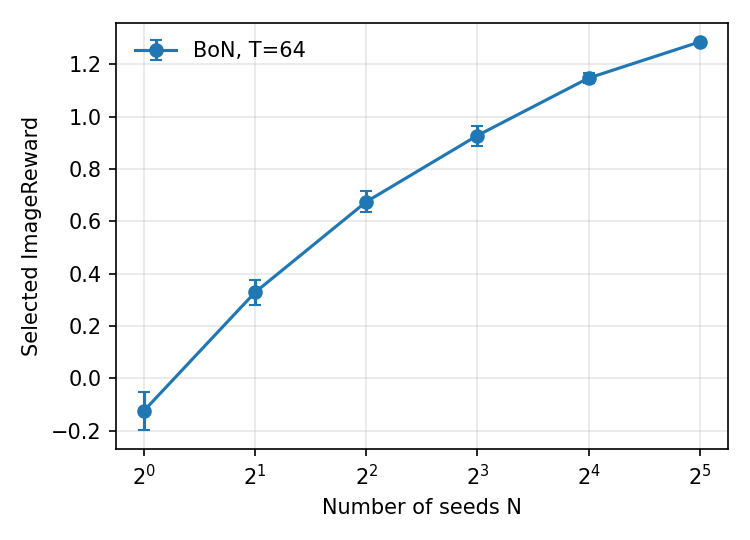

,T,N,N_bar,C_per_prompt,n_prompts,n_groups,ir_mean,ir_std,ir_ci95_lo,ir_ci95_hi
0,64,1,1,64,120,32,-0.124855,0.073036,NaN,NaN
1,64,2,2,128,120,16,0.328278,0.046495,NaN,NaN
2,64,4,4,256,120,8,0.674548,0.040097,NaN,NaN
3,64,8,8,512,120,4,0.928023,0.038147,NaN,NaN
4,64,16,16,1024,120,2,1.147755,0.020129,NaN,NaN
5,64,32,32,2048,120,1,1.286103,NaN,NaN,NaN


In [ ]:
!python bon_replay.py --cache {CACHE} --prompts-path {src_run} --n-values 1,2,4,8,16,32 --out-dir {RES}
!python bon_replay.py --cache {CACHE} --prompts-path {src_run} --n-values 1,2,4,8,16,32 --bootstrap 200 --out-dir {RES}_bootstrap
from IPython.display import Image, display
display(Image(f'{RES}/bon_reward_vs_N.png'))
pd.read_csv(f'{RES}/bon_sweep.csv')

## 9. Handover files to teammates

In [ ]:
import shutil, os
H = f'{PROJ}/handover'; os.makedirs(H, exist_ok=True)
for f in ('metrics.csv', 'compute_log.csv', 'args.json'):
    shutil.copy(f'{CACHE}/{f}', f'{H}/T64_{f}')
shutil.copy(src_run, f'{H}/prompts_run.jsonl')
for d in (RES, f'{RES}_bootstrap', f'{RES}_budget'):
    if os.path.isdir(d): shutil.copytree(d, f'{H}/{os.path.basename(d)}', dirs_exist_ok=True)
shutil.copy('README.md', f'{H}/README.md'); shutil.copy('geneval_bridge.py', f'{H}/geneval_bridge.py')
shutil.make_archive(f'{PROJ}/handover_bon', 'zip', H)
print('Created', f'{PROJ}/handover_bon.zip'); print(sorted(os.listdir(H)))

Created /content/drive/MyDrive/ai6132_its/handover_bon.zip
['README.md', 'T64_args.json', 'T64_compute_log.csv', 'T64_metrics.csv', 'geneval_bridge.py', 'prompts_run.jsonl', 'results_bon', 'results_bon_bootstrap']


## 10. Generate figure for the report

In [ ]:
import json
src = 'geneval_subset_120.jsonl'
rows = [json.loads(l) for l in open(src)]
if NUM_PROMPTS < len(rows):
    per_tag = NUM_PROMPTS // 6
    by_tag = {}
    for r in rows: by_tag.setdefault(r['tag'], []).append(r)
    rows = [r for t in sorted(by_tag) for r in by_tag[t][:per_tag]]
    for i, r in enumerate(rows): r['prompt_id'] = i
src_run = f'{PROJ}/prompts_run.jsonl'

11 a photo of an orange donut and a yellow stop sign
21 a photo of a pink car
45 a photo of two tv remotes
65 a photo of a frisbee right of a motorcycle


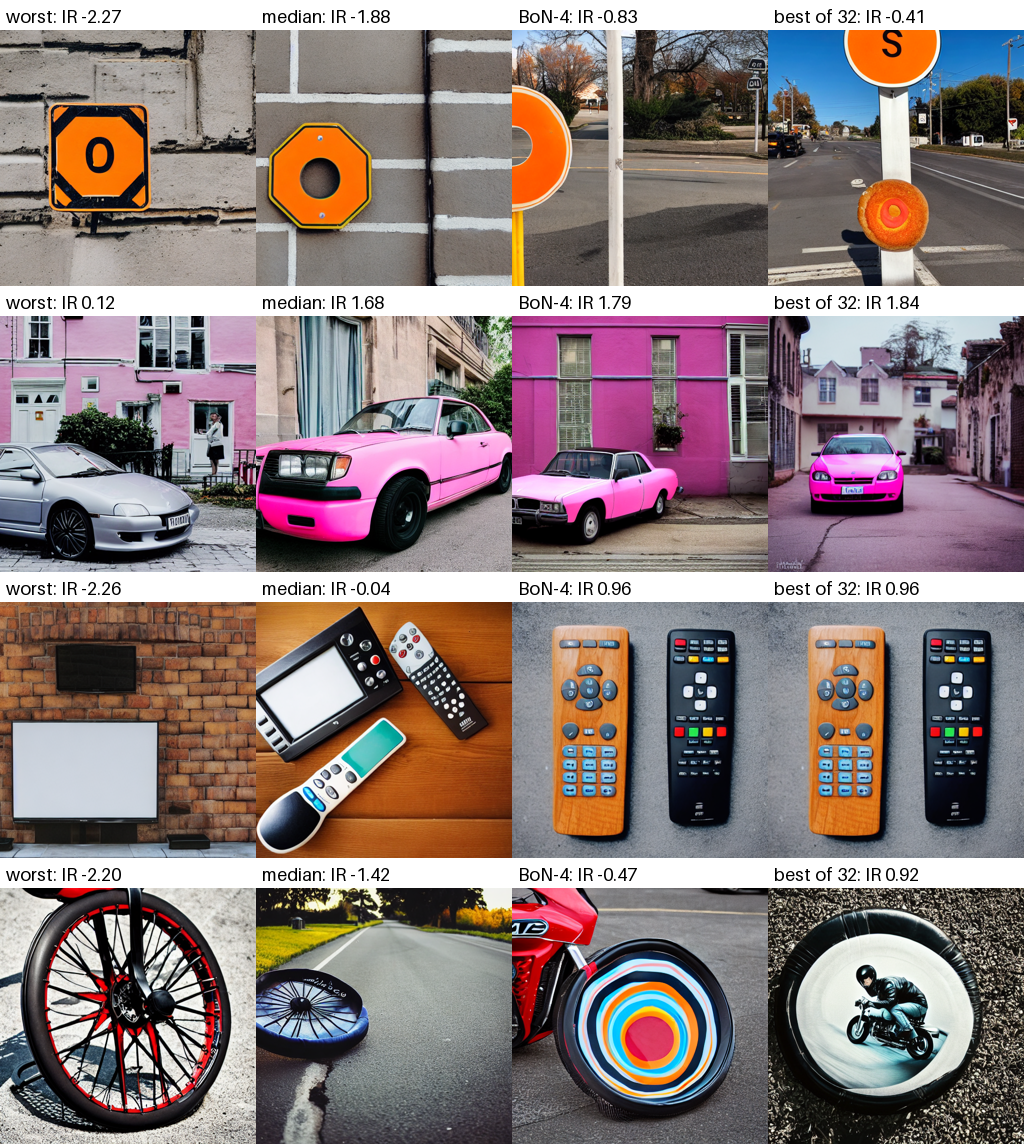

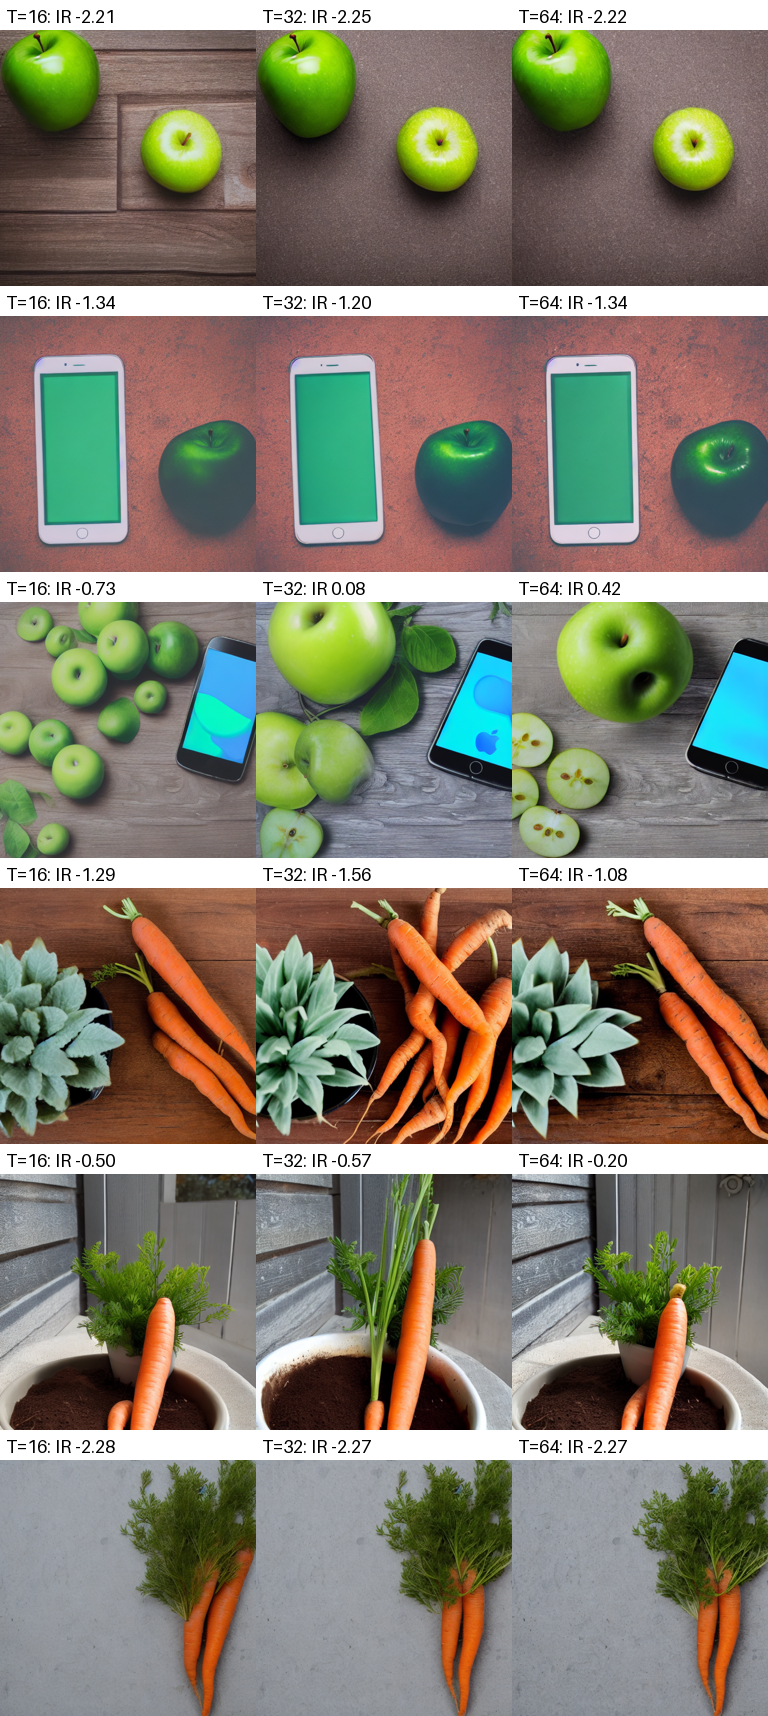

In [ ]:
import os, json, pandas as pd
from PIL import Image, ImageDraw, ImageFont
FIG = f'{PROJ}/figures'; os.makedirs(FIG, exist_ok=True)
try: FONT = ImageFont.load_default(size=18)
except TypeError: FONT = ImageFont.load_default()
prompts = [json.loads(l)['prompt'] for l in open(src_run)]

def final_rewards(T):
    m = pd.read_csv(f'{PROJ}/cache/sd15_geneval_T{T}/metrics.csv')
    return m[m.step == T]

def tile(path, label, size=256):
    c = Image.new('RGB', (size, size + 30), 'white')
    c.paste(Image.open(path).resize((size, size)), (0, 30))
    ImageDraw.Draw(c).text((6, 5), label, fill='black', font=FONT)
    return c

def grid(rows, out):
    w, h = rows[0][0].size
    g = Image.new('RGB', (w * len(rows[0]), h * len(rows)), 'white')
    for r, row in enumerate(rows):
        for c, t in enumerate(row): g.paste(t, (c * w, r * h))
    g.save(out, dpi=(300, 300)); display(g)

# Figure A: worst / median / BoN-4 / best of 32 at T=64
fin = final_rewards(64)
PIDS = [11, 21, 45, 65]                      # change after reading the prompts printed below
rows = []
for p in PIDS:
    print(p, prompts[p])
    d = fin[fin.prompt_id == p].sort_values('image_reward')
    g4 = d[d.seed < p * 32 + 4]              # first group of 4 seeds, same as the BoN sweep
    picks = [('worst', d.iloc[0]), ('median', d.iloc[len(d) // 2]),
             ('BoN-4', g4.loc[g4.image_reward.idxmax()]), ('best of 32', d.iloc[-1])]
    rows.append([tile(f'{CACHE}/samples/{p:05d}/{int(r.seed):05d}.png', f'{n}: IR {r.image_reward:.2f}')
                 for n, r in picks])
grid(rows, f'{FIG}/bon_examples.png')

# Figure B: same seed at T=16 / 32 / 64 (only where all three exist)
fins = {T: final_rewards(T) for T in (16, 32, 64)}
rows = []
for p in (0, 1):
    for s in (p * 32, p * 32 + 1, p * 32 + 2):
        paths = {T: f'{PROJ}/cache/sd15_geneval_T{T}/samples/{p:05d}/{s:05d}.png' for T in (16, 32, 64)}
        if all(os.path.exists(v) for v in paths.values()):
            ir = {T: fins[T].query('seed == @s').image_reward.iloc[0] for T in paths}
            rows.append([tile(paths[T], f'T={T}: IR {ir[T]:.2f}') for T in (16, 32, 64)])
if rows: grid(rows, f'{FIG}/same_seed_vs_steps.png')
else: print('No seed has all three T values; skip Figure B')